## 1. Setup and configuration

In [11]:
import re
import warnings
from math import sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from matplotlib.ticker import PercentFormatter
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

In [12]:
# ---------------------------------------------------------------- input files (outputs of Notebooks 1-2)
STAGE2_FILE = "/home/jovyan/project/Innovation-Management-Group-14/data/flying_drones_stage2_clean.parquet"      # Notebook 2 (required)
BASELINE_FILE = "flying_drones_baseline_prod.parquet"   # Notebook 1 (optional, Section 5.6)

# ---------------------------------------------------------------- caches written by this notebook (delete one to refresh it)
ENRICH_FILE = "flying_drones_stage2_enriched.parquet"   # extra PATSTAT attributes of the corpus applications
LEGAL_FILE = "flying_drones_stage2_legal_events.parquet"
TOTALS_FILE = "patstat_total_families_by_year.parquet"
OUTPUT_DIR = Path("outputs/step1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- PATSTAT access (only for the three cached queries)
USE_PATSTAT = True
ENV = "PROD"                         # the corpus comes from PROD, so enrich it from PROD

# ---------------------------------------------------------------- sector and time window
SECTOR_NAME = "Flying drones"
YEAR_MIN, YEAR_MAX = 2000, 2022      # Notebook 2 kept filing dates in [2000-01-01, 2023-01-01)
LAST_COMPLETE_YEAR = 2022            # the 18-month publication lag leaves the last years incomplete. Notebook 2 already cut at 2023;
                                     # if your PATSTAT edition is older than spring 2024, lower this to 2020 (years after it are shaded)
GRANT_COHORT_MAX = 2018              # grant decisions take 3-5 years: judge "patented or not" only on families up to this year
RECENT = (LAST_COMPLETE_YEAR - 4, LAST_COMPLETE_YEAR)     # last 5 complete years
PAST = (RECENT[0] - 5, RECENT[0] - 1)                     # the 5 years before
GROWTH_WINDOWS = [(2000, 2010), (2010, 2016), (2016, 2022)]   # windows for the growth rates (Section 4)
TOP_N = 15

# ---------------------------------------------------------------- precision found in Notebook 3 (manual validation)
VALIDATION = None                    # e.g. (91, 100) = 91 relevant patents out of 100 annotated; None = not available yet


def answer_box(question, headline, detail):
    "Short framed answer, the same device as in the tutorial."
    display(HTML(f'<div style="border-left:4px solid #1f77b4;background:#f3f8fc;color:#222;padding:10px 14px;margin:8px 0">'
                 f'<b>{question}</b><br>{headline}<br><span style="color:#444">{detail}</span></div>'))


def save_fig(name):
    plt.savefig(OUTPUT_DIR / f"{name}.png", dpi=200, bbox_inches="tight")


def shade_incomplete(ax):
    "Grey band on the years that are still incomplete in PATSTAT."
    if LAST_COMPLETE_YEAR < YEAR_MAX:
        ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15)


def period_label(y):
    "5-year periods starting at YEAR_MIN: 2000-2004, 2005-2009, ..."
    start = YEAR_MIN + 5 * ((y - YEAR_MIN) // 5)
    return f"{start}-{min(start + 4, YEAR_MAX)}"


EXPORT = {}                          # tables collected here are written to OUTPUT_DIR at the end

## 2. Data: the Stage 2 corpus, its quality, and what PATSTAT adds

### 2.1 Load and prepare
We keep one row per application, derive the filing year, give a family to the few applications that have none (`docdb_family_id` = 0 or missing: each is its own family) and parse the CPC codes. In PATSTAT the CPC symbols are padded with blanks (`B64C  39/024`): we remove them so that `B64C39/024` can be compared with a prefix.

In [13]:
raw = pd.read_parquet(STAGE2_FILE)
df = raw.drop_duplicates("appln_id").copy()
print(f"Stage 2 corpus: {len(raw):,} rows, {len(df):,} distinct applications")

df["filing_year"] = pd.to_datetime(df["appln_filing_date"], errors="coerce").dt.year
n_bad_date = df["filing_year"].isna().sum()
df = df[df["filing_year"].between(YEAR_MIN, YEAR_MAX)].copy()
print(f"Dropped {n_bad_date:,} rows with a missing/placeholder date; window {YEAR_MIN}-{YEAR_MAX}: {len(df):,} applications")

# applications without a DOCDB family are treated as their own family
fid = pd.to_numeric(df["docdb_family_id"], errors="coerce")
df["family_id"] = np.where(fid.isna() | (fid <= 0), -df["appln_id"], fid).astype("int64")


def parse_cpc(s):
    "'B64C  39/024, G05D 1/10' -> ['B64C39/024', 'G05D1/10'] (distinct, blanks removed)"
    if not isinstance(s, str):
        return []
    return sorted({re.sub(r"\s+", "", c) for c in s.split(",") if c.strip()})


df["codes"] = df["cpc_codes"].map(parse_cpc)
df.head(3)[["appln_id", "family_id", "appln_auth", "filing_year", "appln_title"]]

Stage 2 corpus: 17,689 rows, 17,689 distinct applications
Dropped 0 rows with a missing/placeholder date; window 2000-2022: 17,689 applications


,appln_id,family_id,appln_auth,filing_year,appln_title
0,43103596,26655181,SE,2000,Unmanned aerial vehicle for low altitude opera...
1,45574542,23143245,WO,2000,METHOD OF REDUCING A NOSE-UP PITCHING MOMENT I...
2,45574555,23142817,WO,2000,UNMANNED AERIAL VEHICLE WITH COUNTER-ROTATING ...


### 2.2 Optional: attributes that the corpus file does not contain
The corpus file has no **grant status**, **IPR type** (patent of invention, utility model...) or **earliest filing year** of the family (the date that the PW asks for). One small PATSTAT query on the 17k `appln_id` of the corpus gets them, and the result is cached. Run it on the TIP platform; if you work offline, the notebook falls back on the earliest filing year *inside the corpus*.

In [14]:
def connect():
    "Connect to PATSTAT only when a query is really needed."
    from epo.tipdata.patstat import PatstatClient
    patstat = PatstatClient(env=ENV)
    return patstat, patstat.orm()


def fetch_enrichment(ids):
    from epo.tipdata.patstat.database.models import TLS201_APPLN
    patstat, db = connect()
    wanted = ["appln_id", "ipr_type", "granted", "earliest_filing_year", "earliest_publn_year",
              "docdb_family_size", "nb_citing_docdb_fam"]
    cols = [getattr(TLS201_APPLN, c) for c in wanted if hasattr(TLS201_APPLN, c)]   # tolerate version differences
    chunks = []
    for start in range(0, len(ids), 5000):                      # chunks keep each query small
        q = db.query(*cols).filter(TLS201_APPLN.appln_id.in_([int(i) for i in ids[start:start + 5000]]))
        chunks.append(patstat.df(q))
    return pd.concat(chunks, ignore_index=True)


enriched = None
if Path(ENRICH_FILE).exists():
    enriched = pd.read_parquet(ENRICH_FILE)
elif USE_PATSTAT:
    try:
        enriched = fetch_enrichment(df["appln_id"].tolist())
        enriched.to_parquet(ENRICH_FILE, index=False)
    except Exception as exc:                                    # no PATSTAT access, or a schema difference
        print("PATSTAT enrichment not available -> reduced analysis. Reason:", repr(exc))

ENRICHED = enriched is not None
if ENRICHED:
    df = df.merge(enriched.drop_duplicates("appln_id"), on="appln_id", how="left")
    print(f"Enriched with: {[c for c in enriched.columns if c != 'appln_id']}")

Enriched with: ['ipr_type', 'granted', 'earliest_filing_year', 'earliest_publn_year', 'docdb_family_size', 'nb_citing_docdb_fam']


In [15]:
# Family year: earliest filing year of the family (PATSTAT) or, without enrichment, earliest filing year inside the corpus
fam_year = df.groupby("family_id")["filing_year"].min()
if ENRICHED and "earliest_filing_year" in df:
    ey = pd.to_numeric(df["earliest_filing_year"], errors="coerce")
    ey = ey.where(ey.between(1900, YEAR_MAX))                   # drops the 9999 / 0 placeholders
    fam_year = ey.groupby(df["family_id"]).min().fillna(fam_year)
    print("Family year = PATSTAT earliest_filing_year (priority-based)")
else:
    print("Family year = earliest filing year of the family's applications INSIDE the corpus (approximation)")
df["family_year"] = df["family_id"].map(fam_year).astype(int)

n_before = df["family_id"].nunique()
df = df[df["family_year"].between(YEAR_MIN, YEAR_MAX)].copy()   # a priority before YEAR_MIN falls outside the window
print(f"{n_before - df['family_id'].nunique():,} families have an earliest year before {YEAR_MIN} and are left out of the family counts")

fam = df.drop_duplicates("family_id")[["family_id", "family_year"]].copy()
fam["period"] = fam["family_year"].map(period_label)
years = range(YEAR_MIN, YEAR_MAX + 1)

quality = pd.Series({
    "applications": len(df),
    "DOCDB families": df["family_id"].nunique(),
    "applications per family": round(len(df) / df["family_id"].nunique(), 2),
    "missing abstract (%)": round((df["appln_abstract"].fillna("").str.strip() == "").mean() * 100, 2),
    "missing CPC codes (%)": round((df["codes"].str.len() == 0).mean() * 100, 2),
    "filing offices": df["appln_auth"].nunique(),
    "first / last filing year": f"{df['filing_year'].min()} / {df['filing_year'].max()}",
}, name="Stage 2 corpus")
quality.to_frame()

Family year = PATSTAT earliest_filing_year (priority-based)
7 families have an earliest year before 2000 and are left out of the family counts


,Stage 2 corpus
applications,17670
DOCDB families,15348
applications per family,1.15
missing abstract (%),0.0
missing CPC codes (%),44.27
filing offices,32
first / last filing year,2000 / 2022


## 3. Volumes: how big is the field?

Three numbers, not one: **applications** (every filing, counted at each office), **families** (distinct inventions) and the **precision-adjusted** volume. Stage 2 is a *high-precision* cut (cosine similarity ≥ 0.65 to the seed centroid, Notebook 2): it keeps 11% of the baseline, so the volumes below are most likely a **lower bound** of the true population, and the share of false positives inside them is known only through the manual validation of Notebook 3.

### 3.1 Applications, families and offices

,applications,families,share of applications (%),cumulative share (%)
appln_auth,,,,
CN,13434,13322,76.0,76.0
US,1515,1229,8.6,84.6
WO,1208,1196,6.8,91.4
EP,479,420,2.7,94.1
KR,353,353,2.0,96.1
CA,129,115,0.7,96.9
AU,114,95,0.6,97.5
JP,109,102,0.6,98.1
RU,93,93,0.5,98.7


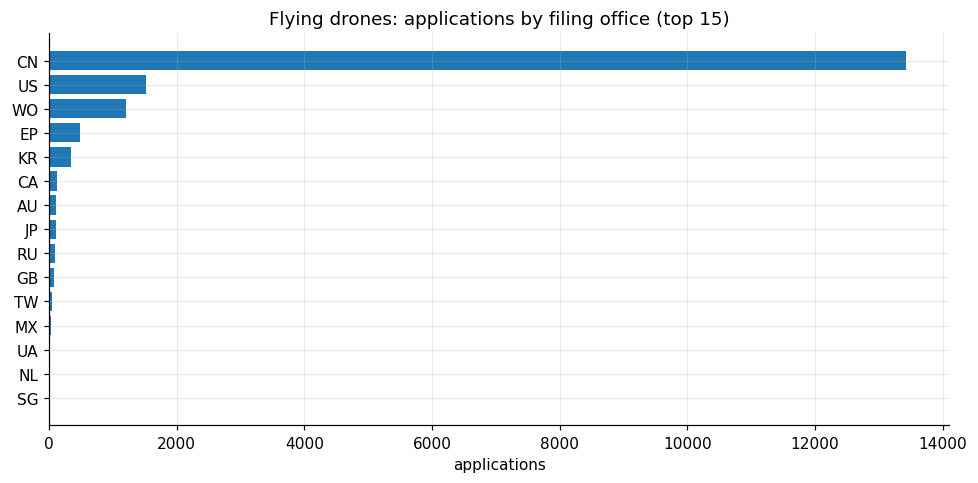

In [16]:
office = (df.groupby("appln_auth")
          .agg(applications=("appln_id", "nunique"), families=("family_id", "nunique"))
          .sort_values("applications", ascending=False))
office["share of applications (%)"] = office["applications"] / office["applications"].sum() * 100
office["cumulative share (%)"] = office["share of applications (%)"].cumsum()
EXPORT["volumes_by_office"] = office.round(2)

display(office.head(TOP_N).round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
top = office.head(TOP_N)["applications"][::-1]
ax.barh(top.index, top.values, color="#1f77b4")
ax.set(title=f"{SECTOR_NAME}: applications by filing office (top {TOP_N})", xlabel="applications")
plt.tight_layout(); save_fig("volumes_by_office"); plt.show()

`WO` are PCT applications (an international route, not a national office) and `EP` are applications at the European Patent Office; both are *routes* that later become national filings. Read the national offices (CN, US, KR, JP...) as the places where protection is actually sought.

### 3.2 Correcting the volume for precision (Notebook 3)
If *k* of the *n* annotated patents were relevant, the share of true positives in the corpus is estimated by *k/n* with a Wilson 95% interval. Multiplying the corpus volume by it gives a plausible range of the **relevant** volume. Fill `VALIDATION` in Section 1 when the five annotators have finished.

In [17]:
def wilson(k, n, z=1.96):
    "Wilson score interval of a proportion (the same formula as in Notebook 3)."
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    margin = z * sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - margin, p, centre + margin


n_fam, n_app = df["family_id"].nunique(), df["appln_id"].nunique()
if VALIDATION:
    k, n = VALIDATION
    lo, p, hi = wilson(k, n)
    adj = pd.DataFrame({"precision": [lo, p, hi],
                        "relevant applications": [n_app * lo, n_app * p, n_app * hi],
                        "relevant families": [n_fam * lo, n_fam * p, n_fam * hi]},
                       index=["lower (95%)", "estimate", "upper (95%)"])
    EXPORT["volumes_precision_adjusted"] = adj.round(3)
    display(adj.round(3))
    print("Precision is applied to families as to applications: an approximation (the sample was drawn on applications).")
else:
    print("VALIDATION is None: report the raw volumes and say that precision is still being measured.")

VALIDATION is None: report the raw volumes and say that precision is still being measured.


,applications,families,families YoY (%),"families, 3-year mean",cumulative families
2000,1,1,NaN,NaN,1
2001,3,9,800.0,NaN,10
2002,11,3,-66.7,4.3,13
2003,4,13,333.3,8.3,26
2004,16,6,-53.8,7.3,32
2005,20,12,100.0,10.3,44
2006,23,20,66.7,12.7,64
2007,18,11,-45.0,14.3,75
2008,28,18,63.6,16.3,93
2009,50,38,111.1,22.3,131


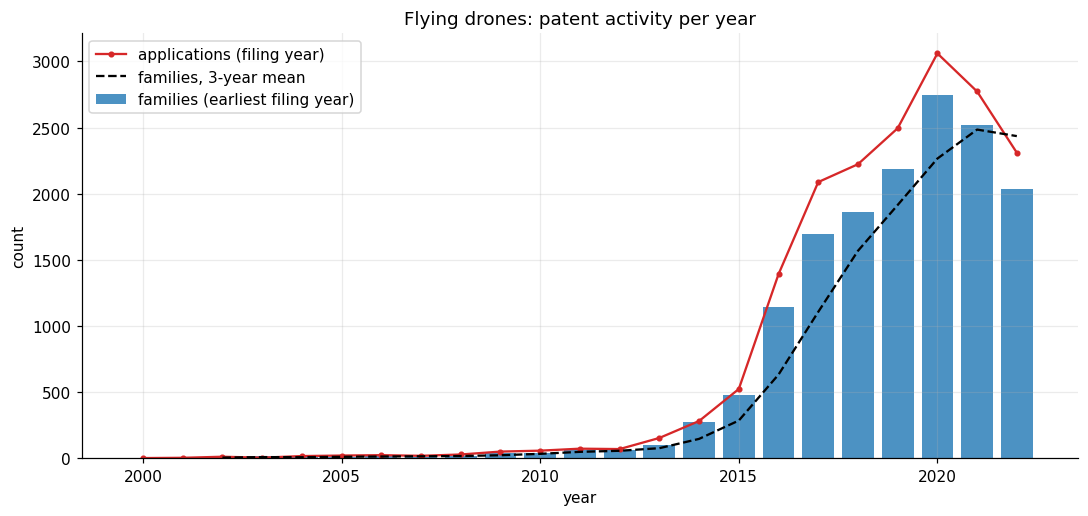

In [18]:
apps_y = df.groupby("filing_year")["appln_id"].nunique().reindex(years, fill_value=0)
fam_y = fam.groupby("family_year").size().reindex(years, fill_value=0)

trend = pd.DataFrame({"applications": apps_y, "families": fam_y})
trend["families YoY (%)"] = trend["families"].pct_change() * 100
trend["families, 3-year mean"] = trend["families"].rolling(3).mean()
trend["cumulative families"] = trend["families"].cumsum()
EXPORT["trend_by_year"] = trend.round(1)
display(trend.round(1))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(trend.index, trend["families"], color="#1f77b4", alpha=0.8, label="families (earliest filing year)")
ax.plot(trend.index, trend["applications"], color="#d62728", marker="o", ms=3, label="applications (filing year)")
ax.plot(trend.index, trend["families, 3-year mean"], color="black", ls="--", label="families, 3-year mean")
shade_incomplete(ax)
ax.set(title=f"{SECTOR_NAME}: patent activity per year", xlabel="year", ylabel="count")
ax.legend()
plt.tight_layout(); save_fig("trend_families_applications"); plt.show()